In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

print("Đã import thư viện thành công.")

Đã import thư viện thành công.


In [17]:
#1 Tạo White Noise theo phân phối chuẩn N(0, 1)
np.random.seed(42)  # Giúp kết quả có thể tái tạo khi chạy lại
white_noise = np.random.normal(loc=0, scale=1, size=1000)

print("Số lượng điểm:", len(white_noise))
print("Trung bình mẫu:", round(np.mean(white_noise), 4))
print("Phương sai mẫu:", round(np.var(white_noise), 4))
print("\n10 giá trị đầu tiên:")
print(np.round(white_noise[:10], 4))

Số lượng điểm: 1000
Trung bình mẫu: 0.0193
Phương sai mẫu: 0.9579

10 giá trị đầu tiên:
[ 0.4967 -0.1383  0.6477  1.523  -0.2342 -0.2341  1.5792  0.7674 -0.4695
  0.5426]


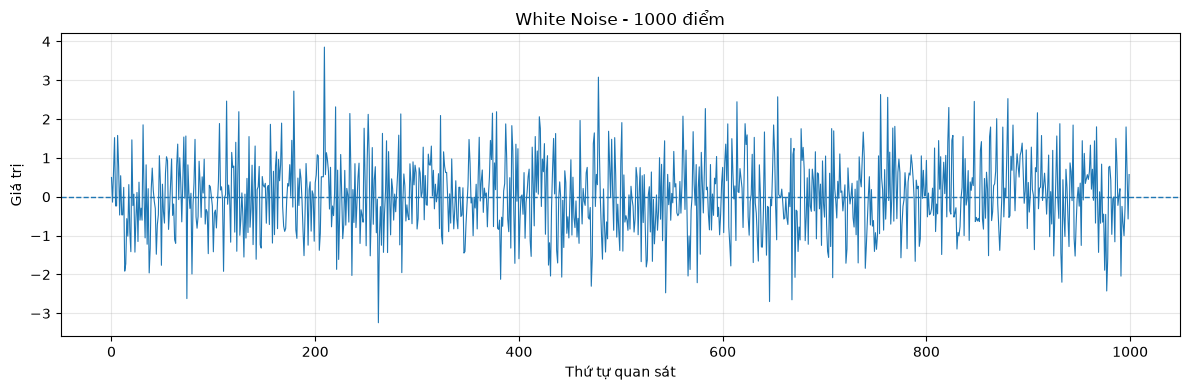

In [18]:
# Vẽ chuỗi White Noise
plt.figure(figsize=(12, 4))
plt.plot(white_noise, linewidth=0.8)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("White Noise - 1000 điểm")
plt.xlabel("Thứ tự quan sát")
plt.ylabel("Giá trị")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

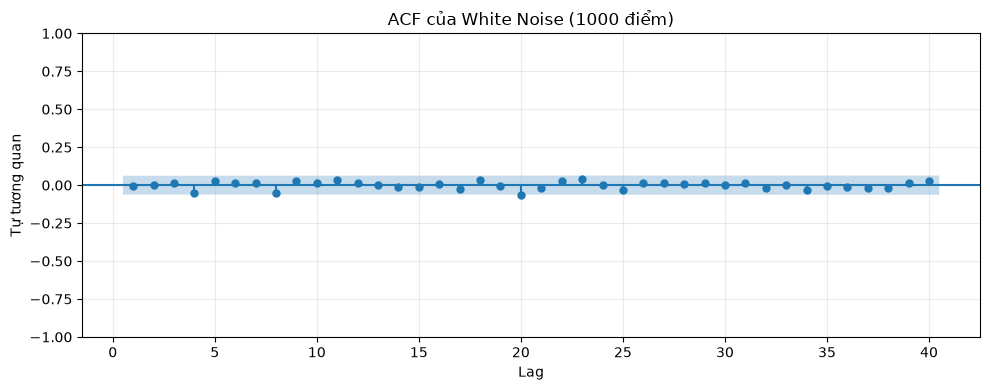

Giới hạn tham khảo xấp xỉ 95%: ±0.062
Lưu ý: không bắt buộc mọi cột ACF đều nằm trong khoảng tin cậy.


In [15]:
#2 Vẽ ACF đến 40 lag
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(white_noise, lags=40, alpha=0.05, zero=False, ax=ax)
ax.set_title("ACF của White Noise (1000 điểm)")
ax.set_xlabel("Lag")
ax.set_ylabel("Tự tương quan")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

gioi_han = 1.96 / np.sqrt(len(white_noise))
print(f"Giới hạn tham khảo xấp xỉ 95%: ±{gioi_han:.3f}")
print("Lưu ý: không bắt buộc mọi cột ACF đều nằm trong khoảng tin cậy.")

In [5]:
#3 Dữ liệu AirPassengers: số hành khách hàng không quốc tế theo tháng,
# từ tháng 1/1949 đến tháng 12/1960 (144 quan sát).
air_values = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432
]

dates = pd.date_range(start="1949-01-01", periods=len(air_values), freq="MS")
air_passengers = pd.Series(air_values, index=dates, name="AirPassengers")

print("Số lượng quan sát AirPassengers:", len(air_passengers))
display(air_passengers.head())

Số lượng quan sát AirPassengers: 144


1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: AirPassengers, dtype: int64

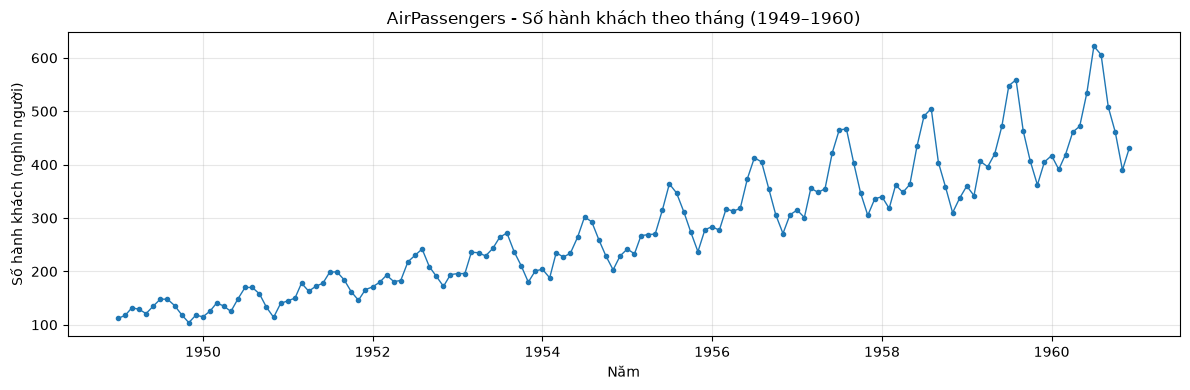

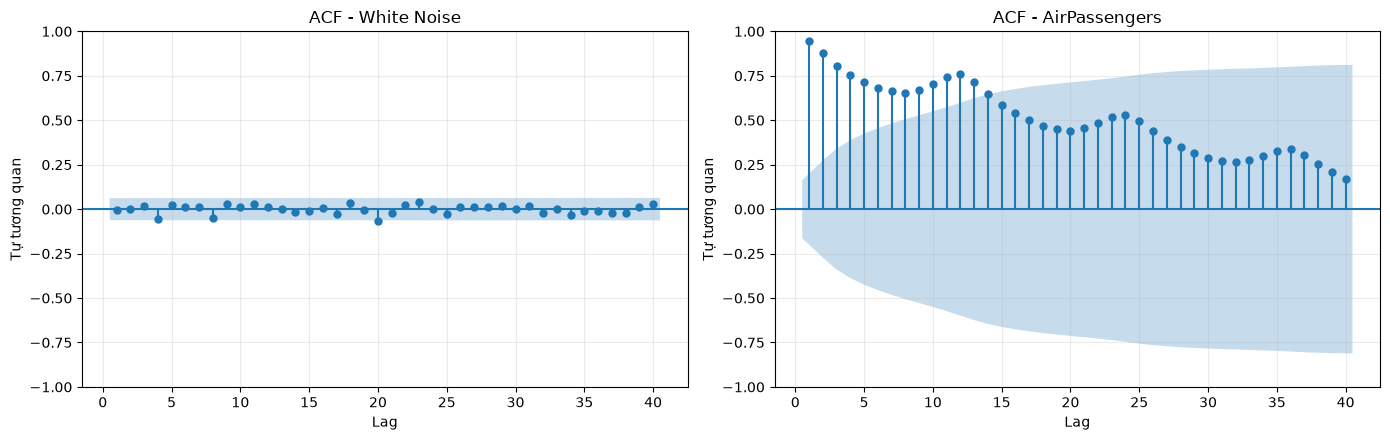

In [6]:
# Vẽ chuỗi AirPassengers
plt.figure(figsize=(12, 4))
plt.plot(air_passengers.index, air_passengers.values, marker=".", linewidth=1)
plt.title("AirPassengers - Số hành khách theo tháng (1949–1960)")
plt.xlabel("Năm")
plt.ylabel("Số hành khách (nghìn người)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Vẽ hai biểu đồ ACF cạnh nhau để so sánh
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_acf(white_noise, lags=40, alpha=0.05, zero=False, ax=axes[0])
axes[0].set_title("ACF - White Noise")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Tự tương quan")

plot_acf(air_passengers.values, lags=40, alpha=0.05, zero=False, ax=axes[1])
axes[1].set_title("ACF - AirPassengers")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Tự tương quan")

for ax in axes:
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

# 5 dòng mô tả sự khác nhau
1. White Noise là chuỗi ngẫu nhiên dao động quanh giá trị trung bình và không có xu hướng tăng hoặc giảm rõ ràng.
2. ACF của White Noise có phần lớn các cột nằm trong khoảng tin cậy 95%, cho thấy không có tự tương quan đáng kể ở phần lớn độ trễ.
3. Ngược lại, AirPassengers có xu hướng tăng theo thời gian và biến động theo mùa.
4. ACF của AirPassengers có nhiều cột vượt khoảng tin cậy 95%, thể hiện sự tự tương quan trong chuỗi.
5. Do đó, AirPassengers có xu hướng và mùa vụ có thể khai thác để xây dựng mô hình dự báo, còn White Noise thuần túy không có quy luật thời gian hữu ích để dự báo.